<a href="https://colab.research.google.com/github/emlluc/Data-201-Project1/blob/main/Project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Project 1

Author: Emme Gunther

In [3]:
#mount Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     KFold, StratifiedKFold, LeaveOneOut, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.datasets import load_iris
from sklearn.metrics import mean_squared_error, roc_auc_score, accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, roc_curve, auc

In [5]:
#CHOSEN DATASET: HEART
heart_raw = pd.read_csv("/content/drive/MyDrive/Data_201/Datasets/heart.csv")
# Using this data, I will test if my chosen predictor variables contribute to the presence/absence of heart disease in the cases in the heart dataset

The dataset:
- the rows hold each person's medical classifications (14 columns), and 303 observations
- the response variable is **target**; it's classes are 0=absence of heart disease, 1=presence of heart disease
- possible predictors: **cp** (chest pain, which is generally correlated with heart problems), **thalach** (tells us if the patient has a faster heart than others), and  **age** (older age = high heart disease presence?)

False positive: when the model labels the patient as having heart disease, but they actually dont
False negative is the opposite; labled negative, but there is a presence of heart disease.

The false negative is the more dangerous type error because patients may walk away without the treatment they need. False positive isn't a good error either, but these cases are more likely to undergo further medical analysis/documentation

Exploring + Preparing the Data

In [6]:
# Check for missing values
heart_raw.isna().sum()

# no missing values, yay!

#Check for duplicated rows
print(heart_raw.duplicated().sum())

# uh oh. However, this does make dense since the official reported number of observations on the dataset's source website is 303.

# Create new dataset, dropping duplicate rows from my needed variables
heart = heart_raw.drop_duplicates()
X = heart[["cp", "thalach", "age"]]
y = heart["target"]

print(heart.duplicated().sum())


723
0


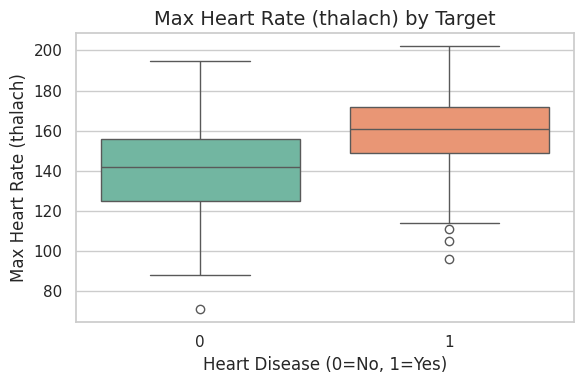

In [28]:
# Max Heart Rate by Target. Graph generated by AI
import seaborn as sns
import matplotlib.pyplot as plt

# Set style
sns.set_theme(style="whitegrid")

# Create a focused plot showing thalach vs target
plt.figure(figsize=(6, 4))
sns.boxplot(
    data=heart,
    x='target',
    y='thalach',
    palette='Set2',
    hue='target',
    legend=False
)

plt.title('Max Heart Rate (thalach) by Target', fontsize=14)
plt.xlabel('Heart Disease (0=No, 1=Yes)', fontsize=12)
plt.ylabel('Max Heart Rate (thalach)', fontsize=12)
plt.tight_layout()
plt.show()

# According to the graph, people with heart disease in the dataset genreally have higher heart rates.. However, there are lower outliers that represent heart diease-positive patients who have lower-than-average heart rates

In [8]:
# Checking the variables types
print(heart.dtypes)

# Count each category in target (response)
print(heart["target"].value_counts())

# the target variables is binary (already encoded), and has relatively normal distribution



age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object
target
1    164
0    138
Name: count, dtype: int64


In [9]:
# Set the predictor features (X) and response variable (y) for the heart dataset
X = heart[["cp", "thalach", "age"]]
y = heart["target"]

# Split the dataset into training (75%) and testing (25%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=1,
    stratify=y
)

# LDA
lda = LinearDiscriminantAnalysis()

# Create k-fold
kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

# Run K-fold cv on training set.
cv_scores = cross_val_score(
    lda,
    X_train,
    y_train,
    cv=kfold
)

# print results
print(cv_scores)
print(cv_scores.mean())

[0.65217391 0.68888889 0.73333333 0.73333333 0.82222222]
0.7259903381642513


Fitting LR, LDA, QDA, KNN


In [10]:
# Fit LR
logreg = LogisticRegression()

# Make prediction
logreg.fit(X_train, y_train)

# Probabilities (calculating the probability of target for every customer in the test set)
prob_target = logreg.predict_proba(X_test)[:, 1]
prob_target

array([0.4099754 , 0.17058285, 0.38072495, 0.78658982, 0.74028604,
       0.2359832 , 0.73744047, 0.24093387, 0.29102389, 0.30194776,
       0.39202012, 0.22576629, 0.64704802, 0.11476256, 0.49804328,
       0.20268655, 0.07246721, 0.32882909, 0.49062649, 0.10643804,
       0.78781043, 0.82184389, 0.71764342, 0.91269301, 0.22406561,
       0.5361307 , 0.95468659, 0.36210104, 0.83182247, 0.78148208,
       0.52429994, 0.85081154, 0.71510683, 0.7789531 , 0.7594689 ,
       0.90112213, 0.95596038, 0.90441209, 0.32886108, 0.89911235,
       0.26401743, 0.33497069, 0.83732951, 0.85488133, 0.9240893 ,
       0.79358088, 0.85733835, 0.70276082, 0.1513941 , 0.7530416 ,
       0.57240103, 0.79685259, 0.33439535, 0.40817168, 0.21383412,
       0.94523175, 0.76537466, 0.89041497, 0.44476121, 0.37660593,
       0.80326153, 0.46143652, 0.13403194, 0.89773728, 0.42634796,
       0.13902175, 0.3742844 , 0.71912365, 0.39074028, 0.74558143,
       0.90946145, 0.70479461, 0.43186715, 0.73302064, 0.12151

In [11]:
# Fit LDA
lda.fit(X_train, y_train)

# Make prediction
lda_pred = lda.predict(X_test)

In [12]:
# Fit QDA
qda = QuadraticDiscriminantAnalysis()

#Fit the model
qda.fit(X_train, y_train)

#Make prediction
qda_pred = qda.predict(X_test)

In [13]:
# Using cv to find best K value

#Test these possible values
k_values = [1, 3, 5, 7, 9, 11, 15, 21]

#create an empty list
cv_scores = []

#Run cross-validation
for k in k_values:

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5
    )

    cv_scores.append(scores.mean())

print(cv_scores)

[np.float64(0.68512077294686), np.float64(0.6941062801932366), np.float64(0.725024154589372), np.float64(0.7207729468599033), np.float64(0.7382608695652173), np.float64(0.7429951690821256), np.float64(0.7341062801932366), np.float64(0.7428019323671496)]


In [14]:
# Use CV to find best K

#Test these possible values
k_values = [1, 3, 5, 7, 9, 11, 15, 21]

# Reset cv_scores
cv_scores = []

#Run cross-validation
for k in k_values:

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5
    )

    cv_scores.append(scores.mean())

print(cv_scores)

# Best choice is k = 11 because it has the highest mean cross-validation accuracy, about 74.30%

[np.float64(0.68512077294686), np.float64(0.6941062801932366), np.float64(0.725024154589372), np.float64(0.7207729468599033), np.float64(0.7382608695652173), np.float64(0.7429951690821256), np.float64(0.7341062801932366), np.float64(0.7428019323671496)]


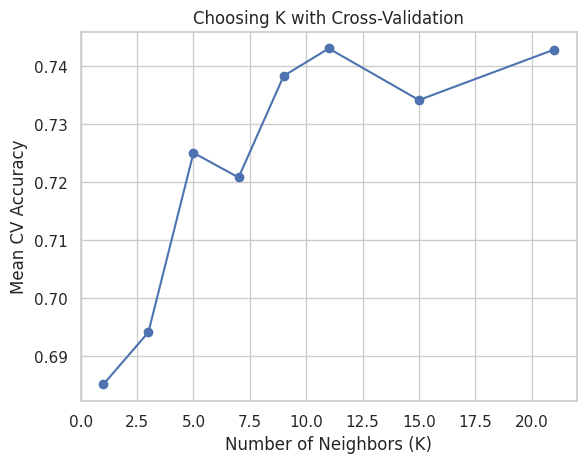

In [15]:
# Plot K vs. Cross-Validation Accuracy

plt.plot(
    k_values,
    cv_scores,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV Accuracy")
plt.title("Choosing K with Cross-Validation")

plt.show()

In [16]:
# Fit final KNN (k=11)
best_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=11)
)

#fit
best_knn.fit(X_train, y_train)

#predict
best_knn_pred = best_knn.predict(X_test)

#evaluate
accuracy_score(y_test, best_knn_pred)



0.7368421052631579

Eval by confusion matrix for each model

I will change the threshold to 0.4, because I care more about if a patient is flagged as positive more than negative (priotitizing false neg over false pos). When I tried a threshold of .3, my results were too skewed.


In [17]:
# Fit each final model using training data
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

lda.fit(X_train, y_train)

qda = QuadraticDiscriminantAnalysis()
qda.fit(X_train, y_train)

knn = KNeighborsClassifier(n_neighbors=11)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=11)

In [18]:
# Probability of defaulting
prob_yes_log = log_reg.predict_proba(X_test)[:, 1]
prob_yes_lda = lda.predict_proba(X_test)[:, 1]
prob_yes_qda = qda.predict_proba(X_test)[:, 1]
prob_yes_knn = knn.predict_proba(X_test)[:, 1]

# Prob_yes_model:
prob_yes_log[:10]
prob_yes_lda[:10]
prob_yes_qda[:10]
prob_yes_knn[:10]

array([0.63636364, 0.18181818, 0.45454545, 0.90909091, 0.63636364,
       0.27272727, 0.72727273, 0.27272727, 0.18181818, 0.18181818])

In [19]:
# Log treshold
pred_30 = np.where(
    prob_yes_log >= 0.40,
    1,
    0
)

# Log confusion
cm30 = confusion_matrix(
    y_test,
    pred_30,
    labels=[0, 1]
)

print(cm30)

# Log metrics
TN30, FP30, FN30, TP30 = cm30.ravel()

accuracy30 = accuracy_score(
    y_test,
    pred_30
)

precision30 = precision_score(
    y_test,
    pred_30,
    pos_label=1
)

recall30 = recall_score(
    y_test,
    pred_30,
    pos_label=1
)

specificity30 = TN30 / (TN30 + FP30)

f1_30 = f1_score(
    y_test,
    pred_30,
    pos_label=1
)

print("Accuracy:", accuracy30)
print("Precision:", precision30)
print("Recall:", recall30)
print("Specificity:", specificity30)
print("F1:", f1_30)

[[22 13]
 [ 5 36]]
Accuracy: 0.7631578947368421
Precision: 0.7346938775510204
Recall: 0.8780487804878049
Specificity: 0.6285714285714286
F1: 0.8


In [20]:
# LDA treshold
pred_30 = np.where(
    prob_yes_lda >= 0.40,
    1,
    0
)

# LDA confusion
cm30 = confusion_matrix(
    y_test,
    pred_30,
    labels=[0, 1]
)

print(cm30)

#LDA metrics
TN30, FP30, FN30, TP30 = cm30.ravel()

accuracy30 = accuracy_score(
    y_test,
    pred_30
)

precision30 = precision_score(
    y_test,
    pred_30,
    pos_label=1
)

recall30 = recall_score(
    y_test,
    pred_30,
    pos_label=1
)

specificity30 = TN30 / (TN30 + FP30)

f1_30 = f1_score(
    y_test,
    pred_30,
    pos_label=1
)

print("Accuracy:", accuracy30)
print("Precision:", precision30)
print("Recall:", recall30)
print("Specificity:", specificity30)
print("F1:", f1_30)

[[23 12]
 [ 5 36]]
Accuracy: 0.7763157894736842
Precision: 0.75
Recall: 0.8780487804878049
Specificity: 0.6571428571428571
F1: 0.8089887640449438


In [21]:
# QDA treshold
pred_30 = np.where(
    prob_yes_qda >= 0.40,
    1,
    0
)

# QDA confusion
cm30 = confusion_matrix(
    y_test,
    pred_30,
    labels=[0, 1]
)

print(cm30)

# QDA metrics
TN30, FP30, FN30, TP30 = cm30.ravel()

accuracy30 = accuracy_score(
    y_test,
    pred_30
)

precision30 = precision_score(
    y_test,
    pred_30,
    pos_label=1
)

recall30 = recall_score(
    y_test,
    pred_30,
    pos_label=1
)

specificity30 = TN30 / (TN30 + FP30)

f1_30 = f1_score(
    y_test,
    pred_30,
    pos_label=1
)

print("Accuracy:", accuracy30)
print("Precision:", precision30)
print("Recall:", recall30)
print("Specificity:", specificity30)
print("F1:", f1_30)

[[23 12]
 [ 6 35]]
Accuracy: 0.7631578947368421
Precision: 0.7446808510638298
Recall: 0.8536585365853658
Specificity: 0.6571428571428571
F1: 0.7954545454545454


In [22]:
# KNN treshold
pred_30 = np.where(
    prob_yes_knn >= 0.40,
    1,
    0
)

# KNN confusion
cm30 = confusion_matrix(
    y_test,
    pred_30,
    labels=[0, 1]
)

print(cm30)

# KNN metrics
TN30, FP30, FN30, TP30 = cm30.ravel()

accuracy30 = accuracy_score(
    y_test,
    pred_30
)

precision30 = precision_score(
    y_test,
    pred_30,
    pos_label=1
)

recall30 = recall_score(
    y_test,
    pred_30,
    pos_label=1
)

specificity30 = TN30 / (TN30 + FP30)

f1_30 = f1_score(
    y_test,
    pred_30,
    pos_label=1
)

print("Accuracy:", accuracy30)
print("Precision:", precision30)
print("Recall:", recall30)
print("Specificity:", specificity30)
print("F1:", f1_30)

[[20 15]
 [ 6 35]]
Accuracy: 0.7236842105263158
Precision: 0.7
Recall: 0.8536585365853658
Specificity: 0.5714285714285714
F1: 0.7692307692307693


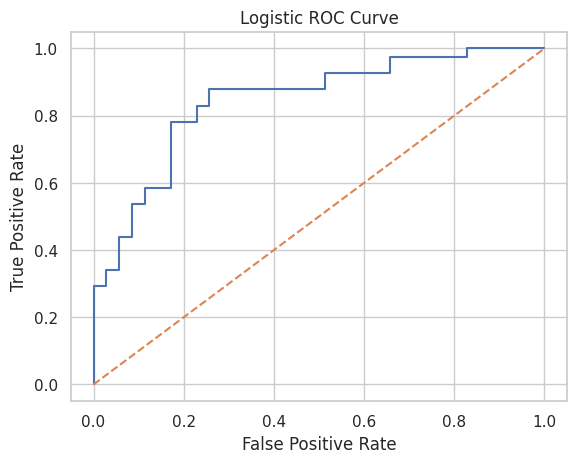

In [23]:
# Log ROC Curve
import matplotlib.pyplot as plt

#convert the response to 0/1
y_test_binary = np.where(
    y_test == 1,
    1,
    0
)

#calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    prob_yes_log
)

#plot
plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic ROC Curve")

plt.show()

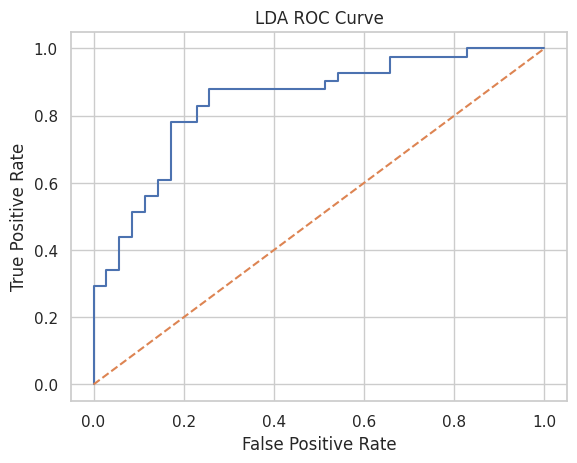

In [24]:
# LDA ROC Curve
import matplotlib.pyplot as plt

#convert the response to 0/1
y_test_binary = np.where(
    y_test == 1,
    1,
    0
)

#calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    prob_yes_lda
)

#plot
plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("LDA ROC Curve")

plt.show()

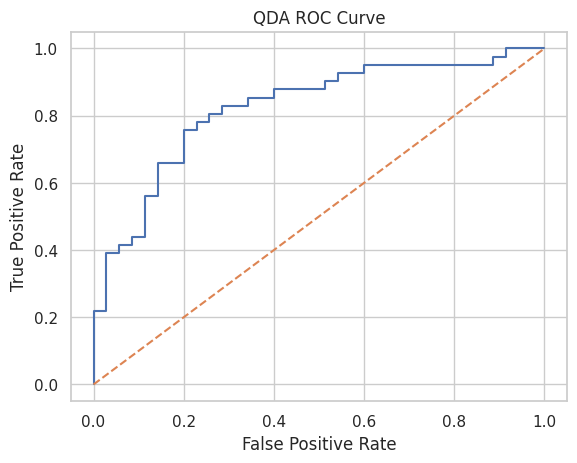

In [25]:
# QDA ROC Curve
import matplotlib.pyplot as plt

#convert the response to 0/1
y_test_binary = np.where(
    y_test == 1,
    1,
    0
)

#calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    prob_yes_qda
)

#plot
plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("QDA ROC Curve")

plt.show()

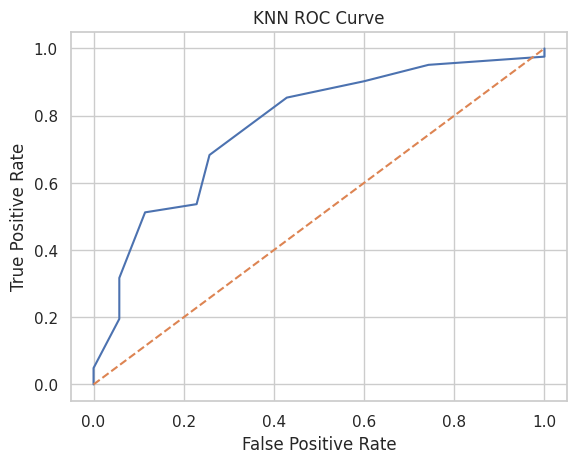

In [26]:
# KNN ROC Curve
import matplotlib.pyplot as plt

#convert the response to 0/1
y_test_binary = np.where(
    y_test == 1,
    1,
    0
)

#calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    prob_yes_knn
)

#plot
plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("KNN ROC Curve")

plt.show()

In [27]:
#Log auc
logauc = roc_auc_score(
    y_test_binary,
    prob_yes_log
)

# LDA auc
ldaauc = roc_auc_score(
    y_test_binary,
    prob_yes_lda
)

#QDA auc
qdaauc = roc_auc_score(
    y_test_binary,
    prob_yes_qda
)

#KNN auc
knnauc = roc_auc_score(
    y_test_binary,
    prob_yes_knn
)


print("LOG AUC:", logauc)
print("LDA AUC:", ldaauc)
print("QDA AUC:", qdaauc)
print("KNN AUC:", knnauc)

LOG AUC: 0.8445993031358885
LDA AUC: 0.8432055749128919
QDA AUC: 0.8229965156794424
KNN AUC: 0.770383275261324


Final Analysis:  

The most important difference (or similarity) is that LDA and Logistic Regression are almost identical in performance, except for accuracy. This means that the Logistic Regression model is better at telling the sick from healthy patients. However, LDA has the best balance across it's metrics at the .4 threshold. The .4 threshold, was lowered from the standard threshold of .5 so the model would prioritize finding the sick patients. LDA having similar metric values means that the model prioritizes finding sick patients, but limits false alarms (healthy patients as sick) in a balance.

However, the model I would deploy would be the Logistic Regression. This is because it beats LDA for accuracy. Testing the models at the .3 threshold compared to the .4 threshold revealed that accuracy is the second-most important metric. If I were to do future tests on this matrix, I could re-use this model and test different thresholds. This would be especially useful if the dataset were to be expanded (the test set was small in my project, which is a limitation of the dataset). With a better dataset, the model metrics may be better at the .4 threshold. This proves that Logistic Regression is the best model additionally because you can re use it after tweaking the features. In the real world, I would be interested in learning if the patients have a family history of heart disease (new predictor).
